05. Retrospective PAMPA Optimization Benchmark
This notebook is the main current PepGate results notebook.

The benchmark asks:
Starting from the least-modified measured backbone pattern for a held-out side-chain scaffold, can a constrained search recover a higher-permeability measured pattern within an edit budget of k = 2?

Three methods are compared under the same frozen settings:
- random search
- generate-and-rank
- guided search
The validation split is used for development. Hyperparameters are then frozen before examining the held-out test split.

In [1]:
from pathlib import Path
import sys
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "analysis").exists():
            return candidate
    raise RuntimeError(
        "Could not find the PepGate repository root. "
        "Open this notebook from inside the PepGate repository."
    )

ROOT = find_repo_root()
SRC = ROOT / "src"
OUTPUTS = ROOT / "outputs"
DATA = ROOT / "data"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PepGate root:", ROOT)

PepGate root: /Users/yeritmaryrodriguezdelgado/Desktop/PEPGATE_YRD


1. Load saved benchmark outputs

In [2]:
VAL_RUNS = OUTPUTS / "validation_pampa_benchmark_runs.csv"
VAL_SUMMARY = OUTPUTS / "validation_pampa_benchmark_summary.csv"
VAL_NO_TOWNSEND = OUTPUTS / "validation_pampa_benchmark_summary_no_townsend.csv"

TEST_RUNS = OUTPUTS / "test_pampa_benchmark_runs.csv"
TEST_SUMMARY = OUTPUTS / "test_pampa_benchmark_summary.csv"
TEST_NO_TOWNSEND = OUTPUTS / "test_pampa_benchmark_summary_no_townsend.csv"

required = [
    VAL_RUNS, VAL_SUMMARY, VAL_NO_TOWNSEND,
    TEST_RUNS, TEST_SUMMARY, TEST_NO_TOWNSEND,
]

for path in required:
    assert path.exists(), f"Missing {path}"

val_runs = pd.read_csv(VAL_RUNS, low_memory=False)
val_summary = pd.read_csv(VAL_SUMMARY, low_memory=False)
val_no_townsend = pd.read_csv(VAL_NO_TOWNSEND, low_memory=False)

test_runs = pd.read_csv(TEST_RUNS, low_memory=False)
test_summary = pd.read_csv(TEST_SUMMARY, low_memory=False)
test_no_townsend = pd.read_csv(TEST_NO_TOWNSEND, low_memory=False)

display(val_summary)
display(test_summary)

,method,n_parents,mean_parent_delta_PAMPA,mean_parent_regret,median_parent_regret,mean_optimum_rate,mean_oracle_calls
0,generate_and_rank,5,0.53496,0.01904,0.0,0.926,8.8
1,guided_search,5,0.55400,0.00000,0.0,1.000,8.2
2,random_search,5,0.53108,0.02292,0.0,0.890,8.8


,method,n_parents,mean_parent_delta_PAMPA,mean_parent_regret,median_parent_regret,mean_optimum_rate,mean_oracle_calls
0,generate_and_rank,4,0.51400,0.01850,0.00365,0.8725,12.25
1,guided_search,4,0.53250,0.00000,0.00000,1.0000,12.00
2,random_search,4,0.52845,0.00405,0.00150,0.9725,12.00


2. Validation benchmark
Settings were frozen after validation:
- edit budget: k = 2
- oracle-call budget: 20
- beam width: 3
- stochastic repetitions: 100

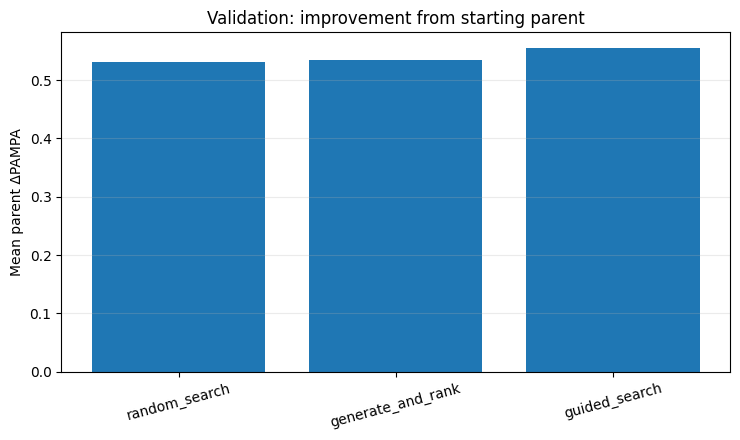

In [3]:
method_order = ["random_search", "generate_and_rank", "guided_search"]

val_plot = val_summary.set_index("method").reindex(method_order).reset_index()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(val_plot["method"], val_plot["mean_parent_delta_PAMPA"])
ax.set_ylabel("Mean parent ΔPAMPA")
ax.set_title("Validation: improvement from starting parent")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

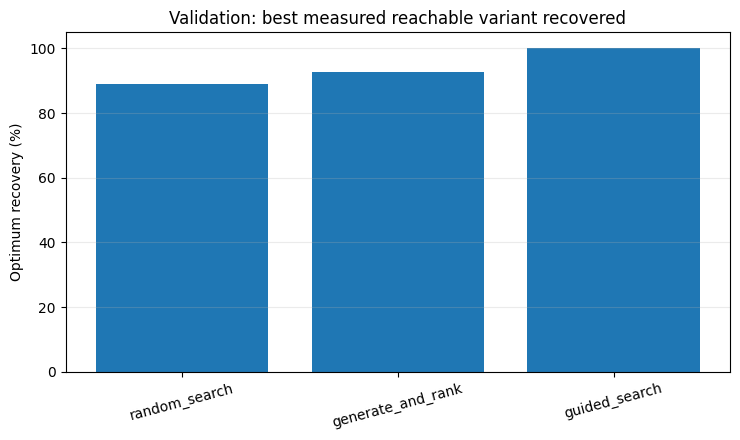

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(val_plot["method"], 100 * val_plot["mean_optimum_rate"])
ax.set_ylabel("Optimum recovery (%)")
ax.set_title("Validation: best measured reachable variant recovered")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

3. Held-out test benchmark

,method,n_parents,mean_parent_delta_PAMPA,mean_parent_regret,median_parent_regret,mean_optimum_rate,mean_oracle_calls
0,random_search,4,0.52845,0.00405,0.00150,0.9725,12.00
1,generate_and_rank,4,0.51400,0.01850,0.00365,0.8725,12.25
2,guided_search,4,0.53250,0.00000,0.00000,1.0000,12.00


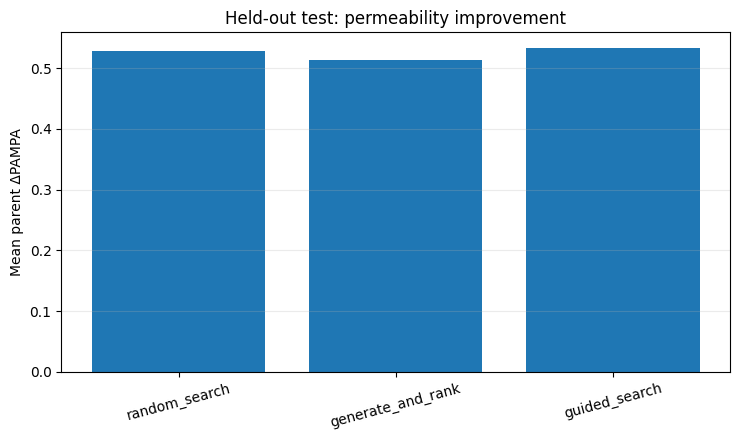

In [5]:
test_plot = test_summary.set_index("method").reindex(method_order).reset_index()

display(test_plot)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(test_plot["method"], test_plot["mean_parent_delta_PAMPA"])
ax.set_ylabel("Mean parent ΔPAMPA")
ax.set_title("Held-out test: permeability improvement")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

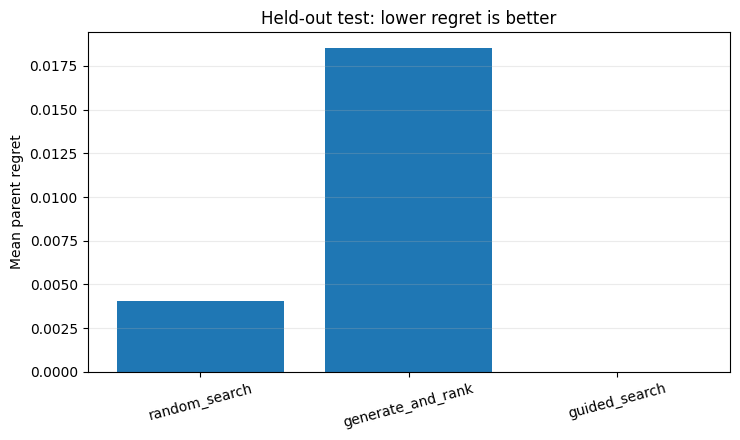

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(test_plot["method"], test_plot["mean_parent_regret"])
ax.set_ylabel("Mean parent regret")
ax.set_title("Held-out test: lower regret is better")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

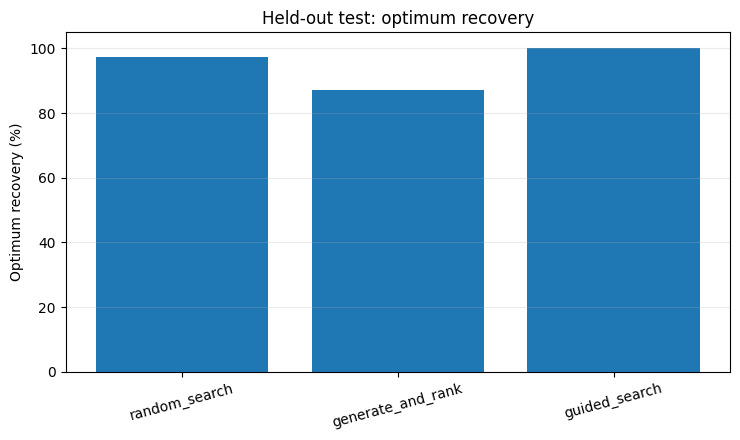

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(test_plot["method"], 100 * test_plot["mean_optimum_rate"])
ax.set_ylabel("Optimum recovery (%)")
ax.set_ylim(0, 105)
ax.set_title("Held-out test: optimum recovery")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

4. Oracle-call efficiency

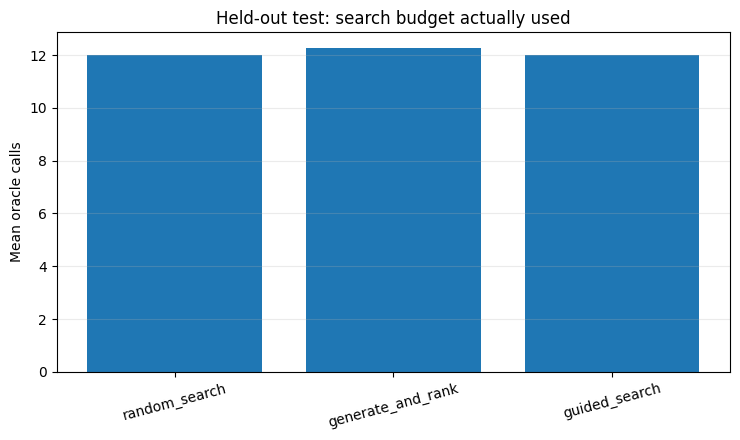

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(test_plot["method"], test_plot["mean_oracle_calls"])
ax.set_ylabel("Mean oracle calls")
ax.set_title("Held-out test: search budget actually used")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

5. Parent-level starting PAMPA vs best reachable measured PAMPA
The benchmark stores one row per seed and method. Starting and optimal values are properties of the parent, so we collapse them to one row per held-out parent.

In [9]:
parent_test = (
    test_runs
    .groupby(["Source", "sidechain_signature"], as_index=False)
    .agg(
        start_PAMPA=("start_PAMPA", "first"),
        optimal_PAMPA=("optimal_PAMPA", "first"),
        n_eligible_patterns=("n_eligible_patterns", "first"),
        n_measured_patterns=("n_measured_patterns", "first"),
    )
)

parent_test["delta_to_optimum"] = (
    parent_test["optimal_PAMPA"] - parent_test["start_PAMPA"]
)

parent_test["parent_label"] = [
    f"{source} | parent {i+1}"
    for i, source in enumerate(parent_test["Source"])
]

display(parent_test)

,Source,sidechain_signature,start_PAMPA,optimal_PAMPA,n_eligible_patterns,n_measured_patterns,delta_to_optimum,parent_label
0,2015_Wang,"('Ala', 'Gly', 'Phe', 'Leu', 'Pro', 'Tyr')",-7.52,-7.15,4,6,0.37,2015_Wang | parent 1
1,2019_Ono,"('Leu', 'Leu', 'Leu', 'Leu', 'Tyr', 'Pro')",-5.59,-5.11,7,8,0.48,2019_Ono | parent 2
2,2020_Townsend,"('Ala', 'Leu', 'beta-hPhe', 'Pro', 'Leu', 'Phe...",-6.49,-5.65,28,137,0.84,2020_Townsend | parent 3
3,2020_Townsend,"('Leu', 'Leu', 'Pro', 'Leu', 'Phe', 'Pro', 'be...",-5.61,-5.17,40,166,0.44,2020_Townsend | parent 4


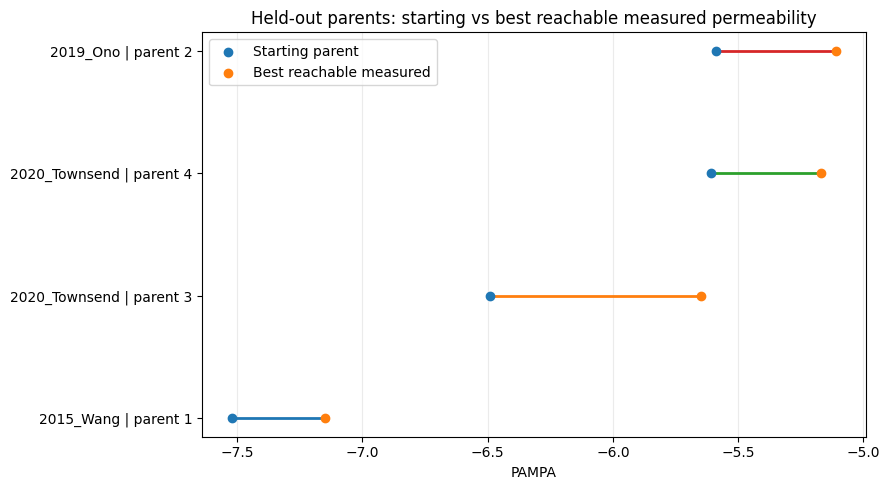

In [10]:
plot_df = parent_test.sort_values("start_PAMPA").reset_index(drop=True)
y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, 5))
for i, row in plot_df.iterrows():
    ax.plot(
        [row["start_PAMPA"], row["optimal_PAMPA"]],
        [i, i],
        linewidth=2,
    )

ax.scatter(plot_df["start_PAMPA"], y, label="Starting parent", zorder=3)
ax.scatter(plot_df["optimal_PAMPA"], y, label="Best reachable measured", zorder=3)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["parent_label"])
ax.set_xlabel("PAMPA")
ax.set_title("Held-out parents: starting vs best reachable measured permeability")
ax.legend()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

6. Parent-level optimizer performance

In [11]:
parent_method = (
    test_runs
    .groupby(["method", "Source", "sidechain_signature"], as_index=False)
    .agg(
        mean_delta_PAMPA=("delta_PAMPA", "mean"),
        mean_regret=("regret", "mean"),
        optimum_rate=("found_optimum", "mean"),
        mean_oracle_calls=("oracle_calls", "mean"),
    )
)

display(parent_method.sort_values(["Source", "method"]))

,method,Source,sidechain_signature,mean_delta_PAMPA,mean_regret,optimum_rate,mean_oracle_calls
0,generate_and_rank,2015_Wang,"('Ala', 'Gly', 'Phe', 'Leu', 'Pro', 'Tyr')",0.3700,0.0000,1.00,3.0
4,guided_search,2015_Wang,"('Ala', 'Gly', 'Phe', 'Leu', 'Pro', 'Tyr')",0.3700,0.0000,1.00,2.0
8,random_search,2015_Wang,"('Ala', 'Gly', 'Phe', 'Leu', 'Pro', 'Tyr')",0.3700,0.0000,1.00,2.0
1,generate_and_rank,2019_Ono,"('Leu', 'Leu', 'Leu', 'Leu', 'Tyr', 'Pro')",0.4800,0.0000,1.00,6.0
5,guided_search,2019_Ono,"('Leu', 'Leu', 'Leu', 'Leu', 'Tyr', 'Pro')",0.4800,0.0000,1.00,6.0
9,random_search,2019_Ono,"('Leu', 'Leu', 'Leu', 'Leu', 'Tyr', 'Pro')",0.4800,0.0000,1.00,6.0
2,generate_and_rank,2020_Townsend,"('Ala', 'Leu', 'beta-hPhe', 'Pro', 'Leu', 'Phe...",0.8327,0.0073,0.95,20.0
3,generate_and_rank,2020_Townsend,"('Leu', 'Leu', 'Pro', 'Leu', 'Phe', 'Pro', 'be...",0.3733,0.0667,0.54,20.0
6,guided_search,2020_Townsend,"('Ala', 'Leu', 'beta-hPhe', 'Pro', 'Leu', 'Phe...",0.8400,0.0000,1.00,20.0
7,guided_search,2020_Townsend,"('Leu', 'Leu', 'Pro', 'Leu', 'Phe', 'Pro', 'be...",0.4400,0.0000,1.00,20.0


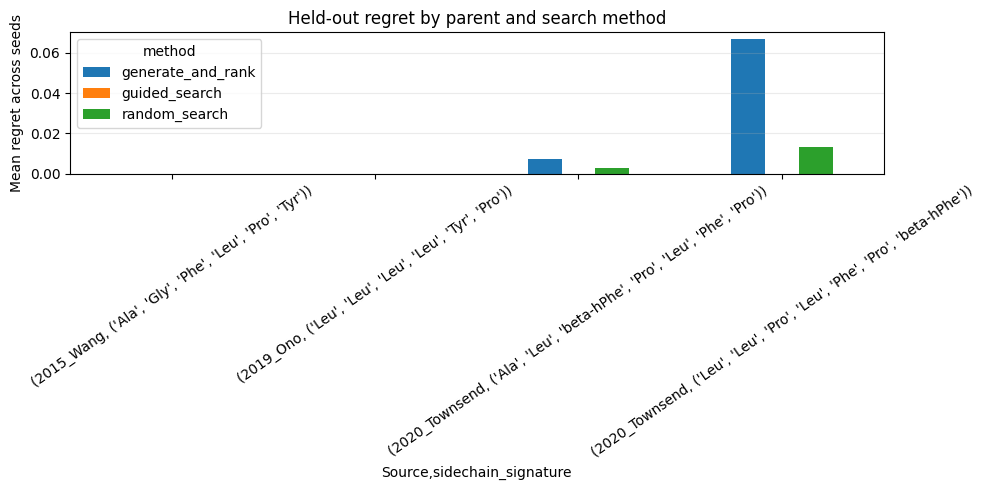

In [12]:
pivot = parent_method.pivot_table(
    index=["Source", "sidechain_signature"],
    columns="method",
    values="mean_regret",
)

ax = pivot.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Mean regret across seeds")
ax.set_title("Held-out regret by parent and search method")
ax.tick_params(axis="x", labelrotation=35)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

7. Townsend sensitivity analysis

In [13]:
print("Validation excluding 2020_Townsend")
display(val_no_townsend)

print("Test excluding 2020_Townsend")
display(test_no_townsend)

Validation excluding 2020_Townsend


,method,n_parents,mean_parent_delta_PAMPA,mean_parent_regret,median_parent_regret,mean_optimum_rate,mean_oracle_calls
0,generate_and_rank,3,0.37,0.0,0.0,1.0,2.666667
1,guided_search,3,0.37,0.0,0.0,1.0,2.666667
2,random_search,3,0.37,0.0,0.0,1.0,2.666667


Test excluding 2020_Townsend


,method,n_parents,mean_parent_delta_PAMPA,mean_parent_regret,median_parent_regret,mean_optimum_rate,mean_oracle_calls
0,generate_and_rank,2,0.425,0.0,0.0,1.0,4.5
1,guided_search,2,0.425,0.0,0.0,1.0,4.0
2,random_search,2,0.425,0.0,0.0,1.0,4.0


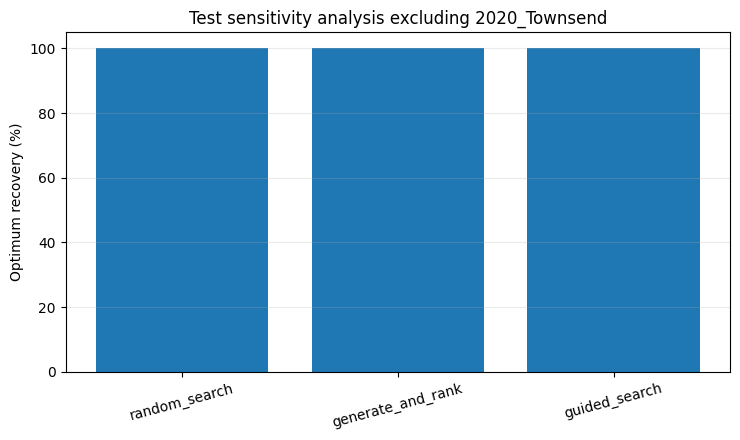

In [14]:
sens = test_no_townsend.set_index("method").reindex(method_order).reset_index()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(sens["method"], 100 * sens["mean_optimum_rate"])
ax.set_ylabel("Optimum recovery (%)")
ax.set_ylim(0, 105)
ax.set_title("Test sensitivity analysis excluding 2020_Townsend")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Interpretation
Use the benchmark conservatively:
- The held-out unit is the side-chain parent scaffold, not individual peptides.
- Search settings were frozen before test evaluation.
- The benchmark is retrospective: only experimentally measured backbone variants can receive a measured-PAMPA score.
- Large Townsend combinatorial libraries make the search methods easier to distinguish.
- After Townsend is excluded, the remaining measured landscapes are small enough that all methods may recover the optimum.
This benchmark therefore supports the statement that the current guided-search implementation can recover high-PAMPA measured variants under the constrained edit formulation. It does not yet establish performance on newly generated, unmeasured candidates.

The next major experiment requires the learned permeability oracle and, later, HELM-BERT proposals.